**ESOPHAGEAL CANCER CLASSIFICATION USING VGG16 FOR WLI IMAGES**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip install tensorflow


**READ THE FILE PATH AND LOAD THE MODEL FOR TRAINING**

In [ ]:
# Define the paths to your dataset directories
train_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/train'
val_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/val'
test_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test'

In [ ]:
import tensorflow as tf

# Define image size and batch size
img_size = (640,640)
batch_size = 32

# Load and preprocess the datasets
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

# Normalize the pixel values to be between 0 and 1
normalization_layer = tf.keras.layers.Rescaling(1./255)

def preprocess(ds):
    ds = ds.map(lambda x, y: (normalization_layer(x), y))
    return ds

train_ds = preprocess(train_ds)
val_ds = preprocess(val_ds)
test_ds = preprocess(test_ds)


Found 751 files belonging to 3 classes.
Found 214 files belonging to 3 classes.
Found 109 files belonging to 3 classes.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Load the VGG16 model pre-trained on ImageNet, without the top classification layers
base_model = tf.keras.applications.VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(640, 640, 3)
)

# Freeze the base model
base_model.trainable = False

# Get the class names from the training dataset before preprocessing
class_names = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
).class_names

# Build the model
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Found 751 files belonging to 3 classes.


**TRAIN THE MODEL**

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100  # Adjust as needed
)


Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 362s 12s/step - accuracy: 0.4022 - loss: 1.1552 - val_accuracy: 0.5888 - val_loss: 0.9329
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.5159 - loss: 0.9489 - val_accuracy: 0.6121 - val_loss: 0.8497
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.5644 - loss: 0.8854 - val_accuracy: 0.6869 - val_loss: 0.8072
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.6467 - loss: 0.8200 - val_accuracy: 0.6869 - val_loss: 0.7562
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.6448 - loss: 0.7829 - val_accuracy: 0.7103 - val_loss: 0.7574
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.7121 - loss: 0.7595 - val_accuracy: 0.7243 - val_loss: 0.7073
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.6967 - loss: 0.7378 - val_accuracy: 0.7430 - val_loss: 0.6722
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.7200 - loss: 0.6930 - val_accuracy: 0.7477 -

**TEST DATA EVALUATION**

In [ ]:
loss, accuracy = model.evaluate(test_ds)
print('Test accuracy:', accuracy)


4/4 ━━━━━━━━━━━━━━━━━━━━ 71s 19s/step - accuracy: 0.8204 - loss: 0.4682
Test accuracy: 0.8348624110221863


**CLASSIFICATION REPORT RESULTS AND CONFUSION MATRIX**

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
  predictions = model.predict(images)
  y_pred.extend(np.argmax(predictions, axis=1))
  y_true.extend(np.argmax(labels, axis=1))


print(classification_report(y_true, y_pred, target_names=class_names))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 761ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
              precision    recall  f1-score   support

   Dysplasia       0.76      0.93      0.84        41
      Normal       0.93      0.79      0.86        34
         SCC       0.87      0.76      0.81        34

    accuracy                           0.83       109
   macro avg       0.85      0.83      0.83       109
weighted avg       0.85      0.83      0.83       109



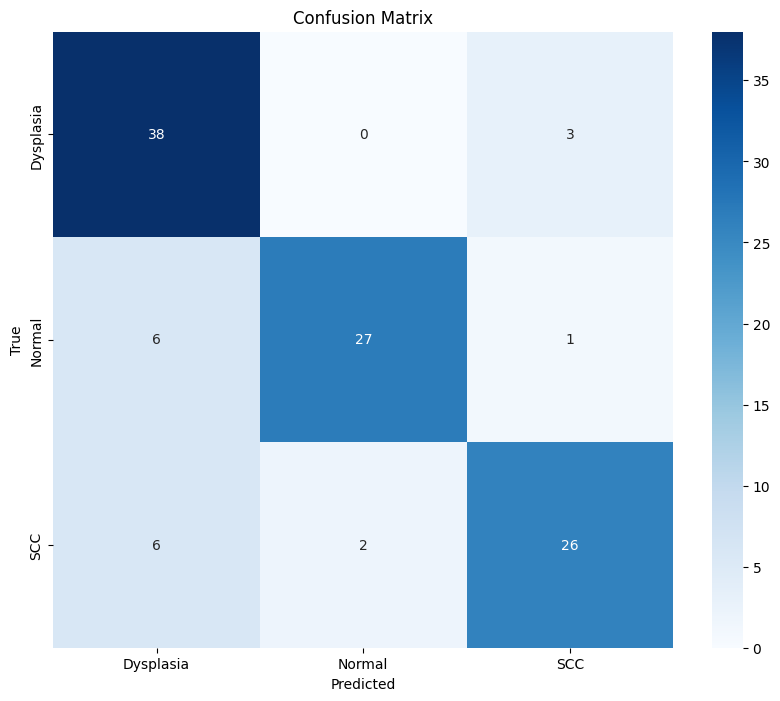

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming you have already computed y_true and y_pred as in the previous code

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


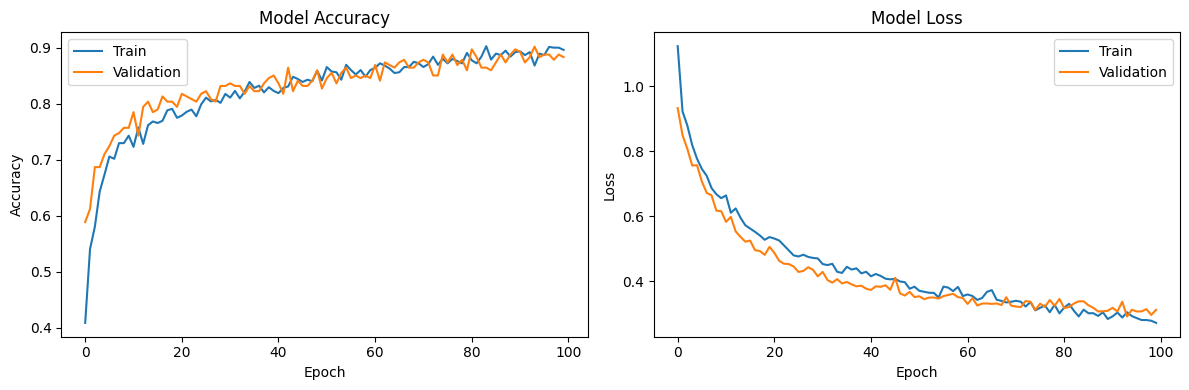

In [ ]:
import matplotlib.pyplot as plt
# Plot training accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper right')

plt.tight_layout()
plt.show()


In [ ]:
model.save('/content/drive/MyDrive/my_model_with_historyvgg16_wli.h5')


In [ ]:
model.save('/content/drive/MyDrive/my_model_vgg16_wli.keras')


**PREDICTION BASED ON THE TEST DATA**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


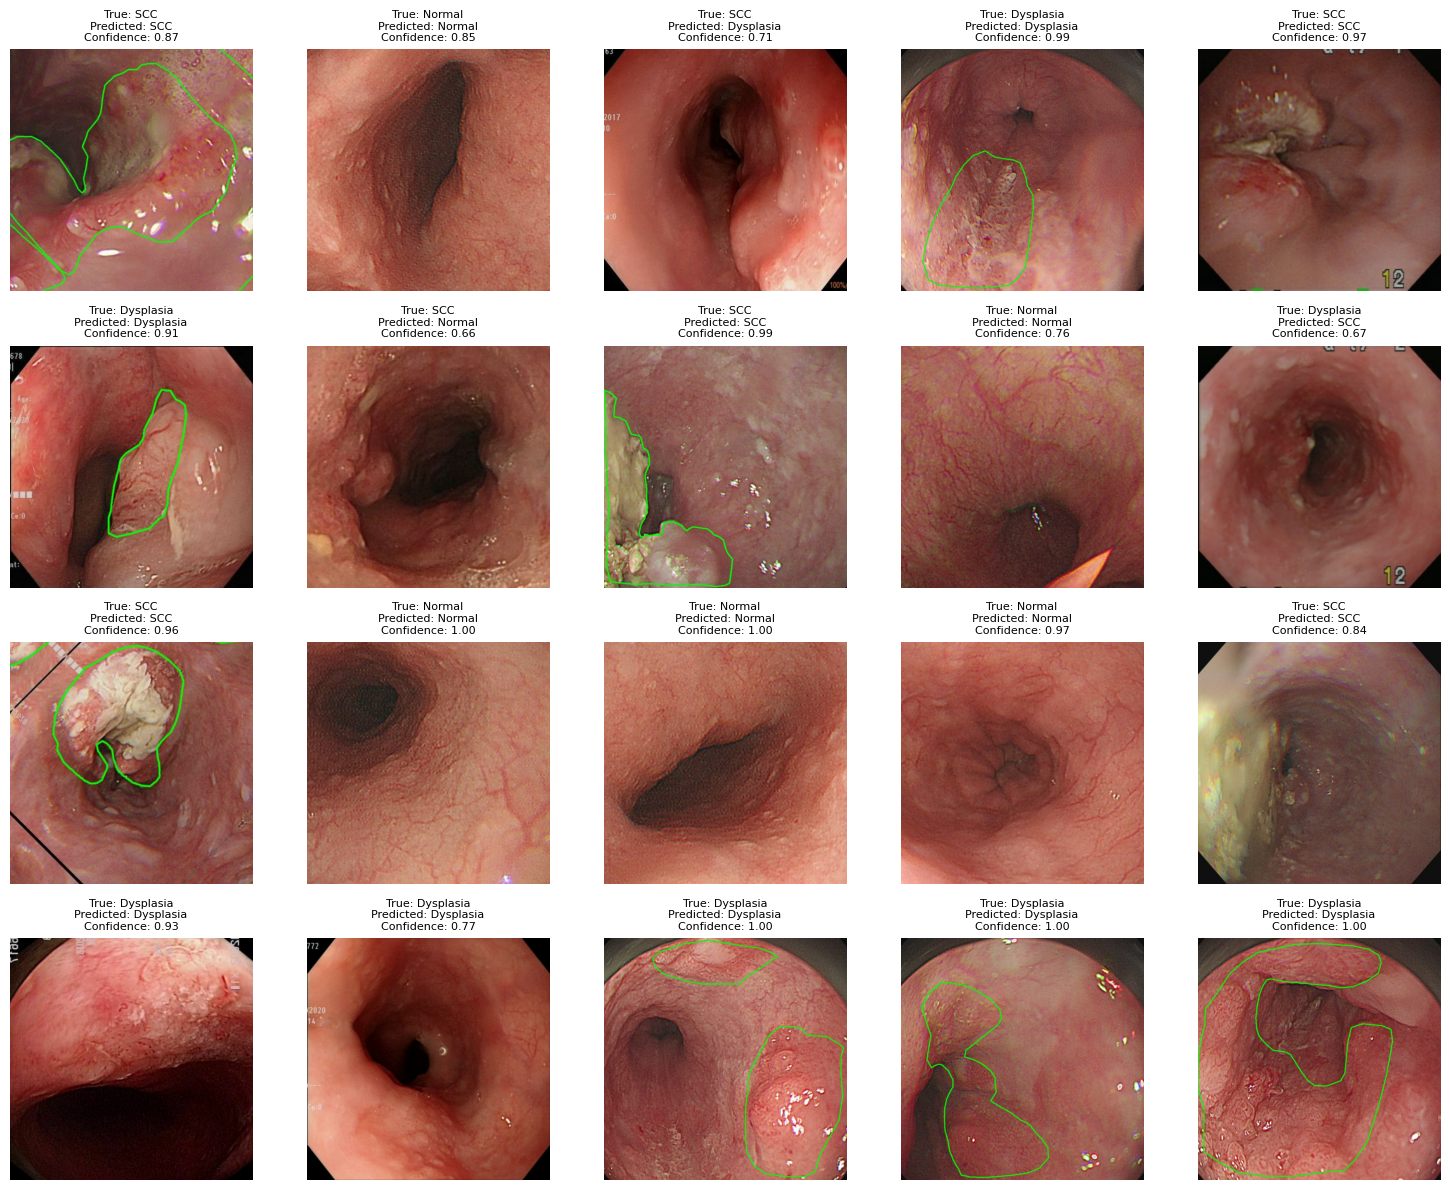

In [ ]:
num_images_to_predict = 20
num_cols = 5  # Number of columns in the grid
num_rows = (num_images_to_predict + num_cols - 1) // num_cols  # Calculate number of rows

plt.figure(figsize=(15, 3 * num_rows))
count = 0
for images, labels in test_ds.take(1):
    for i in range(min(num_images_to_predict, images.shape[0])):
        image = images[i]
        true_label = np.argmax(labels[i])

        # Make prediction
        prediction = model.predict(np.expand_dims(image, axis=0))
        predicted_class = np.argmax(prediction)
        confidence = np.max(prediction)

        # Rescale the image pixels to the range [0, 255]
        image = image.numpy() * 255.0
        image = image.astype("uint8")

        # Display image in a subplot
        plt.subplot(num_rows, num_cols, count + 1)
        plt.imshow(image)
        plt.title(f"True: {class_names[true_label]}\nPredicted: {class_names[predicted_class]}\nConfidence: {confidence:.2f}", fontsize=8)
        plt.axis('off')

        count += 1
        if count >= num_images_to_predict:
            break

plt.tight_layout()
plt.show()


In [ ]:
!mv '/content/drive/MyDrive/my_model_with_historyvgg16_wli.h5' .
!mv '/content/drive/MyDrive/my_model_vgg16_wli.keras' .


In [ ]:
!ls my_model_with_historyvgg16_wli.h5
!ls my_model_vgg16_wli.keras


my_model_with_historyvgg16_wli.h5
my_model_vgg16_wli.keras


In [ ]:
!pwd


/content


In [ ]:
!ls

drive  my_model_vgg16_wli.keras  my_model_with_historyvgg16_wli.h5  sample_data


In [ ]:
!mv my_model_vgg16_wli.keras my_model_with_historyvgg16_wli.h5 '/content/drive/MyDrive/any'
